In [ ]:
%pip install qiskit qiskit_aer qiskit_ibm_runtime numpy pylatexenc

In [25]:
import time
import random
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import DiagonalGate, grover_operator
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

Inserimento delle stringhe di controllo

In [26]:
def revcomp(s):
    return s[::-1].translate(str.maketrans("ACGT", "TGCA"))

REPEATS = [
    ("DM1",   "CTG",   3),   # CTG•CAG     Distrofia miotonica tipo 1
    ("FRAXA", "CGG",   3),   # CGG•CCG     Sindrome X fragile
    ("FRDA",  "GAA",   3),   # GAA•TTC     Atassia di Friedreich
    ("SKDYS", "GAC",   3),   # GAC•GTC     Displasie scheletriche
    ("DM2",   "CCTG",  2),   # CCTG•CAGG   Distrofia miotonica tipo 2
    ("SCA10", "ATTCT", 2),   # ATTCT•AGAAT Atassia spinocerebellare tipo 10
]

CONTROL = {}
for sigla, unit, reps in REPEATS:
    p = unit * reps
    CONTROL[f"{sigla} {unit}x{reps} (+)"] = p
    CONTROL[f"{sigla} {unit}x{reps} (-)"] = revcomp(p)

L_MIN, L_MAX = 12, 14


Generatore di Liste randomiche di dna

In [27]:
def random_dna(L, rng, avoid=()):
    while True:
        s = "".join(rng.choice("ACGT") for _ in range(L))
        if not any(m in s for m in avoid):
            return s

def make_testers(rng, n=10):
    testers = []
    for i in range(n):
        L = rng.randint(L_MIN, L_MAX)
        s = random_dna(L, rng, CONTROL.values())
        planted = None
        if i % 2 == 1:
            planted = rng.choice(list(CONTROL))
            m = CONTROL[planted]
            pos = rng.randrange(0, L - len(m) + 1)
            s = s[:pos] + m + s[pos + len(m):]
        testers.append((f"T{i+1:02d}", s, planted))
    return testers

Definiamo grover per la ricerca

In [28]:
def build_oracle(hits, n):
    signs = [-1 if i in hits else 1 for i in range(2 ** n)]
    qc = QuantumCircuit(n)
    qc.append(DiagonalGate(signs), range(n))
    return qc

def grover_probs(oracle, n, iters):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    if iters > 0:
        qc.compose(grover_operator(oracle).power(iters), inplace=True)
    return qc, Statevector(qc).probabilities()

def grover_search(seq, motif, rng):
    k = len(motif)
    n_pos = len(seq) - k + 1
    n = max(1, int(np.ceil(np.log2(n_pos))))
    N = 2 ** n
    hits = {i for i in range(n_pos) if seq[i:i + k] == motif}
    oracle = build_oracle(hits, n)

    lam, m = 6 / 5, 1.0
    calls = 0
    rounds = int(np.ceil(np.log(np.sqrt(N)) / np.log(lam))) + 6
    for _ in range(rounds):
        j = rng.randrange(0, int(np.ceil(m)))
        _, p = grover_probs(oracle, n, j)
        calls += j + 1
        cand = rng.choices(range(N), weights=p)[0]
        if cand < n_pos and seq[cand:cand + k] == motif:
            return cand, calls
        m = min(lam * m, np.sqrt(N))
    return None, calls

def classical_search(seq, motif):
    n_pos = len(seq) - len(motif) + 1
    for i in range(n_pos):
        if seq[i:i + len(motif)] == motif:
            return i, i + 1
    return None, n_pos

Controlla i 10 tester

In [34]:
def run_screening(rng):
    print(f"{'ID':4} {'Sequenza':16} {'Anomalie trovate':40} "
          f"{'Grover':>7} {'Classico':>9} {'Esito':>6}")
    for tid, seq, planted in make_testers(rng):
        found, g, c, ok = [], 0, 0, True
        for name, motif in CONTROL.items():
            pos, gc = grover_search(seq, motif, rng)
            cpos, cc = classical_search(seq, motif)
            g += gc
            c += cc
            ok &= (pos == cpos)
            if pos is not None:
                found.append(name)
        print(f"{tid:4} {seq:16} {', '.join(found) or 'nessuna':40} "
              f"{g:7d} {c:9d} {'OK' if ok else 'ERR':>6}")


Confronta grover con il metodo classico


In [30]:
def benchmark_match(rng, n_seq=300, p_anom=0.5):
    motifs = list(CONTROL.values())
    cost = {"malato": ([], []), "sano": ([], [])}
    tp = fn = tn = fp = 0
    for _ in range(n_seq):
        L = rng.randint(L_MIN, L_MAX)
        s = random_dna(L, rng, motifs)
        if rng.random() < p_anom:
            m = rng.choice(motifs)
            pos = rng.randrange(0, L - len(m) + 1)
            s = s[:pos] + m + s[pos + len(m):]
        for motif in motifs:
            truth = motif in s
            gpos, gc = grover_search(s, motif, rng)
            _, cc = classical_search(s, motif)
            grp = "malato" if truth else "sano"
            cost[grp][0].append(gc)
            cost[grp][1].append(cc)
            found = gpos is not None
            tp += truth and found
            fn += truth and not found
            tn += (not truth) and (not found)
            fp += (not truth) and found

    print(f"\n{'Gruppo':8} {'N':>5} {'Grover':>8} {'Classico':>9}")
    for grp, (g, c) in cost.items():
        if g:
            print(f"{grp:8} {len(g):5d} {np.mean(g):8.1f} {np.mean(c):9.1f}")
    print(f"TP={tp}  FN={fn}  TN={tn}  FP={fp}  "
          f"Recall={tp / max(tp + fn, 1):.1%}")

Mostra come funziona l'amplificazione

In [31]:
def demo(seq, motif):
    k = len(motif)
    n_pos = len(seq) - k + 1
    n = max(1, int(np.ceil(np.log2(n_pos))))
    N = 2 ** n
    hits = {i for i in range(n_pos) if seq[i:i + k] == motif}
    oracle = build_oracle(hits, n)
    r_opt = max(1, int(np.floor(np.pi / 4 * np.sqrt(N / len(hits)))))
    print(f"\nDemo: {n} qubit, {N} stati, match in posizione {sorted(hits)}")
    for r in range(0, r_opt + 2):
        _, p = grover_probs(oracle, n, r)
        print(f"  iterazioni={r}  P(match)={sum(p[i] for i in hits):.1%}")

Stampa dei risultati

In [33]:
    rng = random.Random(1)
    run_screening(rng)
    benchmark_match(rng)
    demo("ACTGCTGCTGAATC", CONTROL["DM1 CTGx3 (+)"])

ID   Sequenza         Anomalie trovate                          Grover  Classico  Esito
T01  AGATTTTCATAT     nessuna                                      194        48     OK
T02  AGAATAGAATTCT    SCA10 ATTCTx2 (-)                            237        57     OK
T03  CTTCGCCTGATACG   nessuna                                      260        72     OK
T04  ATTCTATTCTTT     SCA10 ATTCTx2 (+)                            169        46     OK
T05  GATACTGTATAGT    nessuna                                      244        60     OK
T06  CCCACCCCTGCCTG   DM2 CCTGx2 (+)                               255        72     OK
T07  CTATGCTTGTGAGT   nessuna                                      257        72     OK
T08  GAAGAAGAAATAGC   FRDA GAAx3 (+)                               250        67     OK
T09  CGGACCGCGGTGTT   nessuna                                      259        72     OK
T10  CCGCCGCCGCTA     FRAXA CGGx3 (-)                              168        45     OK

Gruppo       N   Grover  Classi

Esaminazione con più Basi (per mostrare l'efficenza con la crescita delle basi)

L=   16  Grover malato=   3.9  Grover sano=  22.6  Classico malato=   4.1  Classico sano=    8  (1s)
L=   32  Grover malato=   9.2  Grover sano=  42.2  Classico malato=  13.5  Classico sano=   24  (5s)
L=   64  Grover malato=  13.8  Grover sano=  55.5  Classico malato=  38.8  Classico sano=   56  (9s)
L=  128  Grover malato=  18.4  Grover sano=  77.4  Classico malato=  38.0  Classico sano=  120  (20s)
L=  256  Grover malato=  26.6  Grover sano= 104.2  Classico malato= 125.4  Classico sano=  248  (46s)
L=  512  Grover malato=  36.1  Grover sano= 150.0  Classico malato= 235.6  Classico sano=  504  (125s)


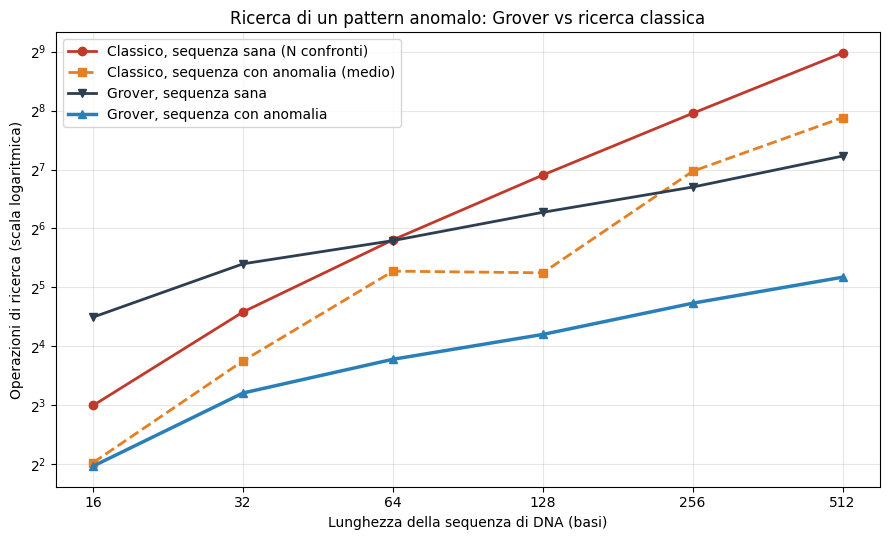

In [ ]:
MOTIF  = CONTROL["DM1 CTGx3 (+)"]
SIZES  = [16, 32, 64, 128, 256, 512]
TRIALS = 12

def scaling_benchmark(rng):
    k = len(MOTIF)
    rows = []
    for L in SIZES:
        n_pos = L - k + 1
        g_mal, c_mal, g_san = [], [], []
        t0 = time.perf_counter()
        for _ in range(TRIALS):
            s = random_dna(L, rng, [MOTIF])
            _, c = grover_search(s, MOTIF, rng)
            g_san.append(c)

            pos = rng.randrange(0, n_pos)
            s2 = s[:pos] + MOTIF + s[pos + k:]
            first = s2.find(MOTIF)
            _, c = grover_search(s2, MOTIF, rng)
            g_mal.append(c)
            c_mal.append(first + 1)

        rows.append(dict(L=L, g_mal=np.mean(g_mal), c_mal=np.mean(c_mal),
                         g_san=np.mean(g_san), c_san=n_pos))
        print(f"L={L:5d}  Grover malato={rows[-1]['g_mal']:6.1f}  "
              f"Grover sano={rows[-1]['g_san']:6.1f}  "
              f"Classico malato={rows[-1]['c_mal']:6.1f}  "
              f"Classico sano={n_pos:5d}  ({time.perf_counter()-t0:.0f}s)")
    return rows

def plot_scaling(rows):
    L = [r["L"] for r in rows]
    plt.figure(figsize=(9, 5.5))
    plt.plot(L, [r["c_san"] for r in rows], "o-",  color="#c0392b", lw=2,
             label="Classico, sequenza sana (N confronti)")
    plt.plot(L, [r["c_mal"] for r in rows], "s--", color="#e67e22", lw=2,
             label="Classico, sequenza con anomalia (medio)")
    plt.plot(L, [r["g_san"] for r in rows], "v-",  color="#2c3e50", lw=2,
             label="Grover, sequenza sana")
    plt.plot(L, [r["g_mal"] for r in rows], "^-",  color="#2980b9", lw=2.5,
             label="Grover, sequenza con anomalia")
    plt.xscale("log", base=2); plt.yscale("log", base=2)
    plt.xticks(L, [str(x) for x in L])
    plt.xlabel("Lunghezza della sequenza di DNA (basi)")
    plt.ylabel("Operazioni di ricerca (scala logaritmica)")
    plt.title("Ricerca di un pattern anomalo: Grover vs ricerca classica")
    plt.grid(alpha=.3, which="both")
    plt.legend(loc="upper left", fontsize=10)
    plt.tight_layout()
    plt.savefig("benchmark.png", dpi=200)
    plt.show()

rows = scaling_benchmark(random.Random(11))
plot_scaling(rows)